# EIS analysis: progress & working notebook

**Goal (the research article's main theme):** use the impedance spectra to show *when* (over the 2300 h durability test) and *where* (across the active area) each physical loss mechanism (ohmic/membrane, ORR charge transfer, mass transport) worsens.

**Status**
- [x] **Zone map verified & oriented**: the 16 EIS zones tile the 29x23 grid cleanly; row 1 = cathode inlet, rows 25–27 = outlet (confirmed by the companion paper: zones 1, 3, 10 are the inlet zones).
- [x] **Data corrections**: (1) the dataset uses two Zahner export formats, polar (|Z|, phase) and cartesian (Z′, Z″); the parser previously misread every cartesian file (all 2300 h data, 1150 h spatial, every sensitivity file), flattening Z″ to ~0. Fixed in `eis_parser.py`. (2) The 1150 h cell folder holds an extra multi-cell measurement (`tst00`, −2.96 V); excluded (`is_multi_cell`). (3) Spatial zones are recorded ~180° rotated, so they are negated. (4) Frequency windows follow the paper (cell 0.1–1180 Hz; zones 1/3/10 0.1–1180 Hz, others 0.1–421 Hz).
- [x] **When (Tier 1, paired over the same 10 cells)**: membrane proxy +8.9 % by 1150 h (paper: +9.75 %); ORR dips (−1.9 %) then rises (+4.0 %); mass transport flat; total +4.9 % at 2300 h.
- [x] **Where (Tier 1, 16 zones × 3 ages)**: strong inlet→outlet gradients; in the first 1150 h ORR falls at the inlet and rises at the outlet; the total-loss increase is concentrated at the outlet.
- [x] **Tier 2 works once seeded from Tier 1**: on the 10-cell mean spectrum, `impedance.py` fits converge consistently at all ages (rms ≈ 0.015). Per-cell fits are much noisier, so the paired aging signal comes from Tier 1.
- [ ] **Cross-check with the polarization curve**: direction agrees, but magnitude (~1.6×) and timing differ (open).
- [ ] **Weak spots**: zone-level membrane attribution (the 421 Hz window leaves part of the ORR arc in the HFR proxy); outlet mass-transport timing differs from the paper.

**Run order:** `python eis_parser.py` (rebuild `eis_raw` with the fixed parser) → `python eis_tier1.py` (build `eis_tier1`) → this notebook.

In [1]:
import os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from contextlib import closing
import eis_tier1 as t1                     # Tier-1 readers (same folder)

HERE = os.getcwd()
PROJECT_DIR = os.path.dirname(HERE)
DB_path = os.path.join(PROJECT_DIR, "cathode_degradation.db")
pd.set_option("display.width", 200)
K = t1.CELL_AREA_CM2 * 1e3                 # Ohm -> mOhm cm2 for cell-level values

def q(sql):
    with closing(sqlite3.connect(f"file:{DB_path}?mode=ro", uri=True)) as con:
        return pd.read_sql_query(sql, con)

eis_cols = q("PRAGMA table_info(eis_raw)").name.tolist()
tables = q("SELECT name FROM sqlite_master WHERE type='table'").name.tolist()
assert "data_format" in eis_cols and "channel" in eis_cols, "eis_raw is from the old parser: run  python eis_parser.py  first"
assert "eis_tier1" in tables, "run  python eis_tier1.py  to build the Tier-1 table"
T1 = q("SELECT * FROM eis_tier1")
print("eis_tier1:", T1.shape)

eis_tier1: (540, 32)


## 1. Zone map (16 spatial-EIS zones → 29x23 grid)

Each zone's `(start, end)` is the top-left and bottom-right segment index of a rectangular block, with `index = row*23 + col` (row-major; segment 24 = row 1, col 1 = first interior cell).

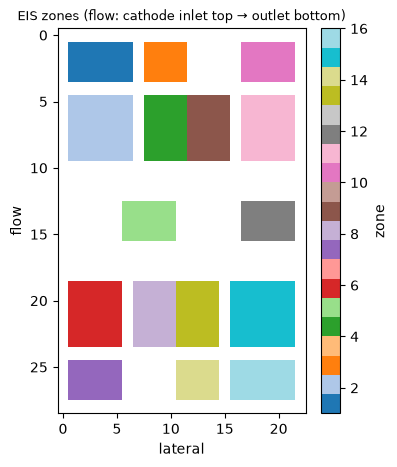

In [2]:
def plate_map(values_by_zone):
    m = np.full((29, 23), np.nan)
    for z, v in values_by_zone.items():
        s, e = t1.ZONES[int(z)]
        (r0, c0), (r1, c1) = divmod(s, 23), divmod(e, 23)
        m[r0:r1+1, c0:c1+1] = v
    return m

plt.figure(figsize=(4, 5))
plt.imshow(plate_map({z: z for z in t1.ZONES}), cmap="tab20", aspect="auto")
plt.title("EIS zones (flow: cathode inlet top → outlet bottom)", fontsize=9)
plt.xlabel("lateral"); plt.ylabel("flow"); plt.colorbar(label="zone"); plt.show()

## 2. Data: export formats & corrections

Two Zahner export formats exist. Polar files store `impedance/Ohm, Phase/deg`; cartesian files store `impedance_R/Ohm, impedance_I/Ohm`. The parser now detects the format per file (`data_format`). It also records the measurement `channel` (cells use CH01–05 and CH07–11; CH06 is the dead U6 channel), which gives a stable cell id across ages for paired comparisons.

In [3]:
display(q("SELECT kind, data_format, COUNT(DISTINCT source_path) AS files FROM eis_raw GROUP BY kind, data_format"))
display(q("SELECT source_path, MAX(potential_V) AS potential_V FROM eis_raw WHERE is_multi_cell=1 GROUP BY source_path"))

,kind,data_format,files
0,cell,cartesian,37
1,cell,polar,51
2,spatial,cartesian,402
3,spatial,polar,51


,source_path,potential_V
0,1150h/50A_25-2A_ampl_454A_tst/50a_25-2a_ampl_4...,-2.96


## 3. Tier 1: reading resistances off the Nyquist plot

No circuit fit, following the paper's Fig. 9a (implemented in `eis_tier1.py`):
- **HFR** (ohmic/membrane). The measured window ends before the arc reaches the real axis, so three estimates are kept: `HFR_1k` (Z′ at 1 kHz, the industry convention and the most robust), `HFR_ext` (circle extrapolation of the ORR arc to Z″ = 0; closest to the true intercept but valid in only ~2/3 of spectra) and `HFR_420` (Z′ at 420 Hz, the only frequency every zone shares).
- **IFR**: Z′ at the valley of −Z″ between the ORR and mass-transport arcs. `single_arc = 1` when there is no valley.
- **LFR**: Z′ where −Z″ crosses zero on the low-frequency side (total).
- ORR ≈ IFR − HFR, mass transport ≈ LFR − IFR. `*_asr` columns are area-specific (mΩ cm²).

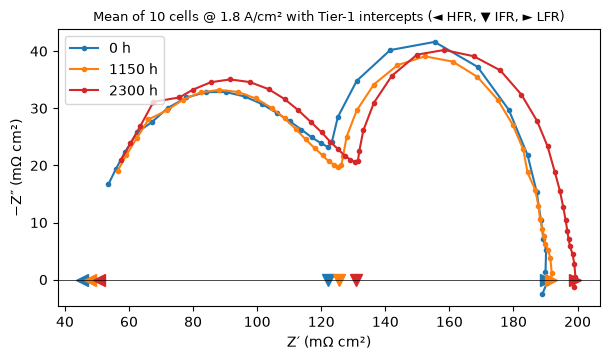

In [4]:
CELL_WHERE = ("kind='cell' AND measurement='nominal' AND ROUND(dc_current_A)=505 "
              "AND is_multi_cell=0 AND age_h={age}")

def mean_spectrum(where):
    d = q(f"SELECT frequency_Hz AS f, Zreal_Ohm AS zr, Zimag_Ohm AS zi FROM eis_raw WHERE {where}")
    d["fr"] = d.f.round(1)
    g = d.groupby("fr").agg(f=("f", "mean"), zr=("zr", "mean"), zi=("zi", "mean")).sort_values("f")
    return g.f.values, g.zr.values, g.zi.values

fig, ax = plt.subplots(figsize=(7, 3.6))
for age, col in zip((0, 1150, 2300), ("C0", "C1", "C3")):
    f, zr, zi = mean_spectrum(CELL_WHERE.format(age=age))
    fs, zrs, nz = t1._prep(f, zr, zi, t1.FMAX_CELL)
    r = t1.tier1(f, zr, zi, t1.FMAX_CELL)
    ax.plot(zrs*K, nz*K, "o-", ms=3, color=col, label=f"{age} h")
    for key, mk in (("HFR_ext", "<"), ("IFR", "v"), ("LFR", ">")):
        if np.isfinite(r[key]):
            ax.plot(r[key]*K, 0, mk, color=col, ms=9)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("Z′ (mΩ cm²)"); ax.set_ylabel("−Z″ (mΩ cm²)")
ax.set_title("Mean of 10 cells @ 1.8 A/cm² with Tier-1 intercepts (◄ HFR, ▼ IFR, ► LFR)", fontsize=9)
ax.legend(); plt.show()

## 4. When: cell-level change, paired over the same 10 cells

Each cell is compared with itself (`channel`), which removes the cell-to-cell offset and makes small aging changes measurable. `t` = change / standard error (|t| > ~2.3 is significant for n = 10).

In [5]:
cell = T1[(T1.kind == "cell") & (T1.measurement == "nominal") & (T1.dc_current_A.round() == 505)].copy()
cell["ORR_1k_asr"] = cell.IFR_asr - cell.HFR_1k_asr
METRICS = {"HFR_1k_asr": "membrane proxy (HFR @ 1 kHz)", "ORR_1k_asr": "ORR (IFR − HFR_1k)",
           "R_MT_t1_asr": "mass transport (LFR − IFR)", "LFR_asr": "total (LFR)"}

def paired_change(df, value, id_col="channel"):
    w = df.pivot_table(index=id_col, columns="age_h", values=value)
    rows = []
    for a in [c for c in w.columns if c != 0]:
        d = (w[a] - w[0]).dropna()
        se = d.std(ddof=1) / np.sqrt(len(d))
        rows.append({"age_h": a, "BoL mean": w[0].mean(), "change": d.mean(), "SE": se,
                     "change %": 100 * d.mean() / w[0].mean(), "t": d.mean() / se, "n": len(d)})
    return pd.DataFrame(rows)

when = pd.concat({lab: paired_change(cell, c) for c, lab in METRICS.items()}, names=["metric"]).droplevel(1)
when.round(2)

,age_h,BoL mean,change,SE,change %,t,n
metric,,,,,,,
membrane proxy (HFR @ 1 kHz),1150,53.84,4.80,0.49,8.92,9.83,10
membrane proxy (HFR @ 1 kHz),2300,53.84,6.05,0.57,11.24,10.59,10
ORR (IFR − HFR_1k),1150,68.14,-1.30,0.27,-1.91,-4.79,10
ORR (IFR − HFR_1k),2300,68.14,2.72,0.65,4.00,4.22,10
mass transport (LFR − IFR),1150,68.50,-1.65,1.43,-2.42,-1.15,10
mass transport (LFR − IFR),2300,68.50,0.50,1.65,0.72,0.30,10
total (LFR),1150,190.48,1.84,1.33,0.97,1.39,10
total (LFR),2300,190.48,9.27,1.75,4.87,5.30,10


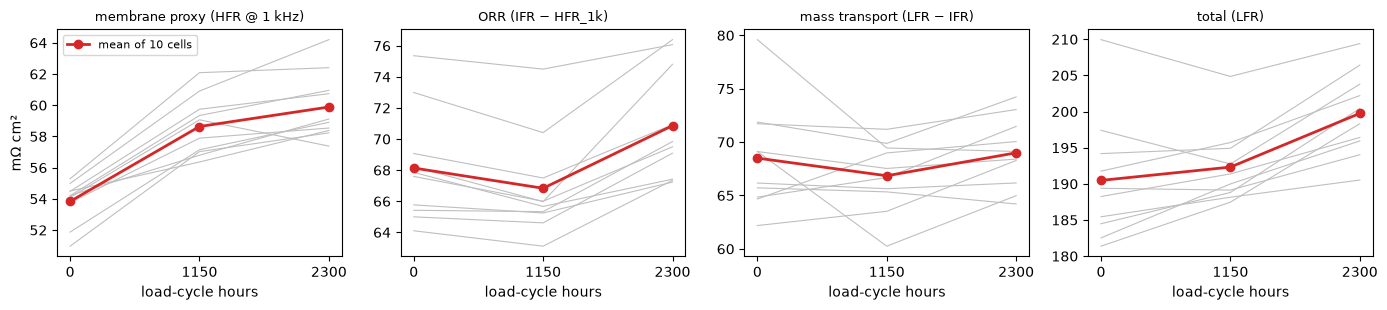

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (c, lab) in zip(axs, METRICS.items()):
    w = cell.pivot_table(index="channel", columns="age_h", values=c)
    for _, row in w.iterrows():
        ax.plot(row.index, row.values, color="0.75", lw=0.8)
    ax.plot(w.columns, w.mean(), "o-", color="C3", lw=2, label="mean of 10 cells")
    ax.set_title(lab, fontsize=9); ax.set_xlabel("load-cycle hours"); ax.set_xticks([0, 1150, 2300])
axs[0].set_ylabel("mΩ cm²"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Note: `HFR_1k` still sits on the tail of the ORR arc, so part of its rise at 2300 h is the ORR increase leaking in. The seeded circuit fit in section 7 separates the two: the fitted membrane resistance rises a few percent by 1150 h and then plateaus.

## 5. Cross-check: LFR vs the DC slope of the polarization curve

At a fixed operating point, the low-frequency limit of the impedance should approach the local slope of the polarization curve, −dU/dj. The slope is taken from a linear fit through the steady-state holds above 1.2 A/cm².

In [7]:
def dc_slope(age, air=0, jmin=1.2):
    df = q(f'SELECT "I.S.set [A]" AS s, "j.S.act [A/cm2]" AS j, "U.S.AveCell [V]" AS u '
           f'FROM polarization_raw WHERE age_h={age} AND air_air_start={air}')
    s = df.s.values
    b = [0] + [i for i in range(1, len(s)) if abs(s[i] - s[i-1]) > 0.5] + [len(s)]
    holds = pd.DataFrame([df.iloc[max(a, e - 60):e][["j", "u"]].mean() for a, e in zip(b[:-1], b[1:]) if e - a >= 60])
    holds = holds[holds.j > jmin]
    return -np.polyfit(holds.j, holds.u, 1)[0] * 1e3          # mOhm cm2

xc = pd.DataFrame({"R_dc polarization": {a: dc_slope(a) for a in (0, 1150, 2300)},
                   "LFR (EIS)": cell.groupby("age_h").LFR_asr.mean()})
xc["LFR / R_dc"] = xc["LFR (EIS)"] / xc["R_dc polarization"]
display(xc.round(2))
rev = pd.DataFrame({"right after load cycle": {a: dc_slope(a, 0) for a in (1500, 2300)},
                    "after air/air start": {a: dc_slope(a, 1) for a in (1500, 2300)}})
print("Reversible-loss effect on R_dc (mΩ cm²):"); display(rev.round(1))

,R_dc polarization,LFR (EIS),LFR / R_dc
0,102.91,190.48,1.85
1150,120.60,192.32,1.59
2300,122.43,199.75,1.63


Reversible-loss effect on R_dc (mΩ cm²):


,right after load cycle,after air/air start
1500,123.4,119.6
2300,122.4,119.8


**Reading the cross-check.** Both measurements rise monotonically with age, but they are not interchangeable:
- **Magnitude:** LFR is ~1.6× R_dc. Expected for two reasons. −Z″ turns inductive below ~0.2 Hz, so the impedance keeps falling toward DC below the measured window. And the polarization path is non-isothermal (coolant outlet rises ~5 K across the high-current holds), which flattens dU/dj.
- **Timing:** R_dc rises mostly by 1150 h, while LFR rises mainly by 2300 h. Reversible losses do **not** explain this: air/air start lowers R_dc by only ~3 %. The most likely remaining cause is that R_dc is a large-signal chord over 1.2–1.8 A/cm² that picks up the growing high-current curvature, which a single small-signal point at 1.8 A/cm² does not see. Open.

## 6. Where: zone resistances across three ages

Zone values are zone impedance × zone area (mΩ cm²), the normalization of the paper's Table 4. They are internally consistent but systematically lower than the cell-level ASR (the CDDM zones are not electrically decoupled), so compare zones with each other and over time, not with the cell.

**Single-arc rule.** Zones that never show a resolved mass-transport arc (the O₂-rich inlet/upper zones) are treated as mass-transport-free: MT = 0, ORR = LFR − HFR_420. A zone that has a clear second arc at some ages but not at others (zone 8) is marked *unresolved* at those ages rather than forced to MT = 0, which would misassign its mass transport to ORR.

In [8]:
sp = T1[(T1.kind == "spatial") & (T1.measurement == "nominal") & (T1.dc_current_A.round() == 505)
        & (T1.is_reference == 0)].copy()
REGION = {1: "1 inlet", 3: "1 inlet", 10: "1 inlet", 2: "2 upper", 4: "2 upper", 9: "2 upper", 11: "2 upper",
          5: "3 middle", 12: "3 middle", 6: "4 lower", 8: "4 lower", 13: "4 lower", 15: "4 lower",
          7: "5 outlet", 14: "5 outlet", 16: "5 outlet"}
sp["region"] = sp.zone.map(REGION)

MT_FREE_MAX = 5.0          # mOhm cm2: every resolved MT value below this -> mass-transport-free zone
resolved = sp[sp.single_arc == 0].groupby("zone").R_MT_t1_asr.max()
mt_free = {z for z in sp.zone.unique() if z not in resolved.index or resolved[z] < MT_FREE_MAX}
two, free = sp.single_arc == 0, sp.zone.isin(mt_free)
sp["ORR_asr"] = np.where(two, sp.IFR_asr - sp.HFR_420_asr, np.where(free, sp.LFR_asr - sp.HFR_420_asr, np.nan))
sp["MT_asr"] = np.where(two, sp.R_MT_t1_asr.clip(lower=0), np.where(free, 0.0, np.nan))
print("mass-transport-free zones:", sorted(int(z) for z in mt_free))
print("unresolved ORR/MT splits (zone, age):", sp.loc[sp.ORR_asr.isna(), ["zone", "age_h"]].astype(int).values.tolist())

keep = sp.groupby("zone").ORR_asr.apply(lambda s: s.notna().all())
s15 = sp[sp.zone.isin(set(keep[keep].index))]          # zones resolved at all three ages
ours = s15.groupby("age_h")[["HFR_420_asr", "ORR_asr", "MT_asr"]].agg(["mean", "std"])
paper = pd.DataFrame({("HFR_420_asr", "mean"): [14.50, 15.91, 14.91], ("HFR_420_asr", "std"): [2.18, 2.99, 3.96],
                      ("ORR_asr", "mean"): [17.62, 17.17, 20.40], ("ORR_asr", "std"): [3.68, 5.94, 5.78],
                      ("MT_asr", "mean"): [32.22, 32.34, 35.76], ("MT_asr", "std"): [29.90, 28.78, 33.79]},
                     index=pd.Index([0, 1150, 2300], name="age_h"))
display(pd.concat({"this work (Tier 1)": ours, "paper Table 4 (fit)": paper}).round(1))

mass-transport-free zones: [1, 3, 4, 9, 10, 11]
unresolved ORR/MT splits (zone, age): [[8, 1150], [8, 2300]]


HFR_420_asr      ORR_asr      MT_asr      
                                 mean  std    mean  std   mean   std
                    age_h                                           
this work (Tier 1)  0            18.9  2.3    17.2  5.7   29.1  37.6
                    1150         20.5  2.8    17.4  7.4   39.1  50.1
                    2300         21.7  2.7    17.4  7.5   35.9  44.3
paper Table 4 (fit) 0            14.5  2.2    17.6  3.7   32.2  29.9
                    1150         15.9  3.0    17.2  5.9   32.3  28.8
                    2300         14.9  4.0    20.4  5.8   35.8  33.8

In [9]:
lfr = sp.pivot_table(index="region", columns="age_h", values="LFR_asr")        # LFR: all 16 zones
orr = s15.pivot_table(index="region", columns="age_h", values="ORR_asr")
mt = s15.pivot_table(index="region", columns="age_h", values="MT_asr")
display(pd.concat({"total LFR": lfr, "ORR": orr, "MT": mt}, axis=1).round(1))
display(pd.DataFrame({"ORR 0→1150 h %": 100 * (orr[1150] / orr[0] - 1),
                      "ORR 1150→2300 h %": 100 * (orr[2300] / orr[1150] - 1),
                      "total LFR 0→2300 h %": 100 * (lfr[2300] / lfr[0] - 1)}).round(1))

total LFR                 ORR                MT              
age_h         0      1150   2300  0     1150  2300  0      1150   2300
region                                                                
1 inlet       34.8   34.6   36.4  13.8  11.3  12.8   0.0    0.1    0.0
2 upper       36.1   36.5   38.3  18.2  15.6  14.1   0.1    0.3    2.3
3 middle      50.3   54.6   57.3  12.7  11.8  12.7  20.1   22.4   23.7
4 lower       83.7   99.1   88.0  13.7  16.8  16.5  56.1   71.1   53.3
5 outlet     121.9  157.2  158.2  25.8  30.1  30.6  76.1  109.0  107.5

,ORR 0→1150 h %,ORR 1150→2300 h %,total LFR 0→2300 h %
region,,,
1 inlet,-18.3,13.1,4.6
2 upper,-14.2,-9.8,6.1
3 middle,-6.8,7.7,13.8
4 lower,22.8,-1.5,5.2
5 outlet,16.9,1.6,29.8


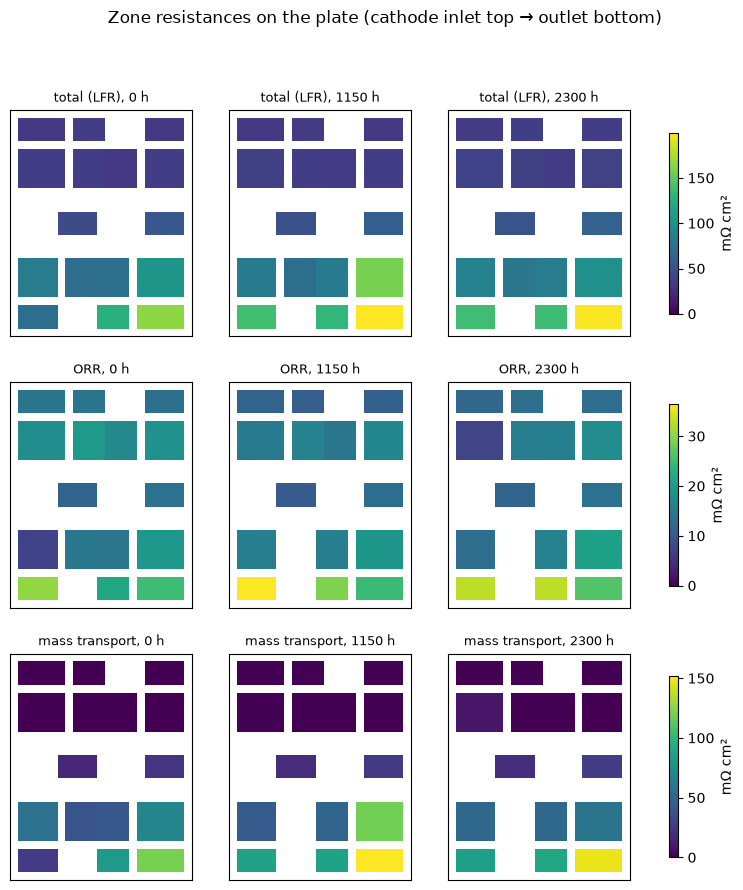

In [10]:
fig, axs = plt.subplots(3, 3, figsize=(10, 10))
for i, (col, lab) in enumerate([("LFR_asr", "total (LFR)"), ("ORR_asr", "ORR"), ("MT_asr", "mass transport")]):
    vmax = np.nanmax(sp[col])
    for j, age in enumerate((0, 1150, 2300)):
        v = sp[sp.age_h == age].set_index("zone")[col]
        im = axs[i, j].imshow(plate_map(v), aspect="auto", cmap="viridis", vmin=0, vmax=vmax)
        axs[i, j].set_title(f"{lab}, {age} h", fontsize=9)
        axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
    fig.colorbar(im, ax=axs[i, :], shrink=0.8, label="mΩ cm²")
fig.suptitle("Zone resistances on the plate (cathode inlet top → outlet bottom)")
plt.show()

## 7. Tier 2: equivalent circuit seeded from Tier 1

The circuit R0 + two R-CPE is fitted with `impedance.py`. The initial guess comes from the Tier-1 intercepts (R0 ≈ HFR, R1 ≈ IFR − HFR, R2 ≈ LFR − IFR, CPE time constants from the arc-apex frequencies). With a generic starting guess the fit lands in different local minima at different ages; seeded, it converges consistently. Spectra without a valley (single arc) return `None`.

In [11]:
from impedance.models.circuits import CustomCircuit

def fit_seeded(f, zr, zi, fmax=t1.FMAX_CELL, negate=False):
    r = t1.tier1(f, zr, zi, fmax, negate)
    fs, zrs, nz = t1._prep(f, zr, zi, fmax, negate)            # high -> low f, nz = -Z''
    i_orr = t1._first_peak(nz)
    half = len(nz) // 2
    i_mt = half + int(np.argmax(nz[half:]))
    R0 = r["HFR_ext"] if np.isfinite(r["HFR_ext"]) else (r["HFR_1k"] if np.isfinite(r["HFR_1k"]) else zrs.min())
    R1, R2, a = r["IFR"] - R0, r["LFR"] - r["IFR"], 0.85
    if not (np.isfinite(R1) and R1 > 0 and R2 > 0):
        return None                                             # single arc: nothing to split
    Q1, Q2 = 1 / (R1 * (2*np.pi*fs[i_orr])**a), 1 / (R2 * (2*np.pi*fs[i_mt])**a)
    o = np.argsort(fs)
    ff, Z = fs[o], (zrs - 1j*nz)[o]
    circ = CustomCircuit("R0-p(R1,CPE1)-p(R2,CPE2)", initial_guess=[R0, R1, Q1, a, R2, Q2, a])
    circ.fit(ff, Z)
    p = circ.parameters_
    tau1, tau2 = (p[1]*p[2])**(1/p[3]), (p[4]*p[5])**(1/p[6])
    R_orr, R_mt = (p[1], p[4]) if tau1 <= tau2 else (p[4], p[1])     # faster arc = ORR
    rms = np.sqrt((np.abs(circ.predict(ff) - Z)**2).mean()) / np.abs(Z).mean()
    return {"R_membrane": p[0], "R_ORR": R_orr, "R_MT": R_mt, "rms": rms}

rows = []
for age in (0, 1150, 2300):
    s = fit_seeded(*mean_spectrum(CELL_WHERE.format(age=age)))
    rows.append({"age_h": age, **{k: (v if k == "rms" else v * K) for k, v in s.items()}})
tier2 = pd.DataFrame(rows).set_index("age_h")
tier2.round(3)

,R_membrane,R_ORR,R_MT,rms
age_h,,,,
0,47.563,71.904,71.399,0.016
1150,49.324,73.267,68.731,0.013
2300,48.861,78.902,71.117,0.015


In [12]:
# the same seeded fit per cell -> paired Tier-2 changes
rows = []
for (age, ch), _ in cell.groupby(["age_h", "channel"]):
    s = fit_seeded(*mean_spectrum(CELL_WHERE.format(age=age) + f" AND channel={int(ch)}"))
    if s is not None:
        rows.append({"age_h": age, "channel": ch, **{k: (v if k == "rms" else v * K) for k, v in s.items()}})
t2cell = pd.DataFrame(rows)
print("median fit rms:", round(t2cell.rms.median(), 4), "| fits:", len(t2cell))
pd.concat({m: paired_change(t2cell, m) for m in ("R_membrane", "R_ORR", "R_MT")}, names=["metric"]).droplevel(1).round(2)

median fit rms: 0.0181 | fits: 30


,age_h,BoL mean,change,SE,change %,t,n
metric,,,,,,,
R_membrane,1150,44.75,1.40,4.74,3.13,0.30,10
R_membrane,2300,44.75,2.92,3.21,6.52,0.91,10
R_ORR,1150,74.72,2.20,5.58,2.95,0.39,10
R_ORR,2300,74.72,5.47,3.67,7.32,1.49,10
R_MT,1150,72.80,-4.39,1.57,-6.02,-2.79,10
R_MT,2300,72.80,-1.70,1.25,-2.33,-1.35,10


Per-cell circuit fits are far less precise than the Tier-1 intercepts: the paired standard errors are ~5–10× larger (e.g. membrane t ≈ 0.3 vs ≈ 10 for `HFR_1k`). In each single-cell spectrum R0 trades off against the ORR arc's CPE parameters. So use **Tier 1 for the paired aging signal** and the **seeded fit on the 10-cell mean spectrum for the three-way decomposition**.

## 8. Findings vs the paper (need updated)

| Mechanism | This work | Paper (Fensterle et al.) | |
|---|---|---|---|
| Membrane, when | +8.9 % by 1150 h (HFR @ 1 kHz, paired n = 10); fitted R0 rises a few % then plateaus | +9.75 % over the first 1150 h (spatial mean); cell: slight increase | agree |
| ORR, when | −1.9 % at 1150 h, +4.0 % at 2300 h (paired); fit +9–10 % at 2300 h | "initially decreases slightly and then increases" | agree |
| Mass transport, when | flat (n.s.) at cell level | "practically constant" | agree |
| Total, when | +4.9 % at 2300 h | minor effects at cell level | agree |
| Gradients, where | total 3.5×, ORR and MT rise from inlet to outlet; membrane higher at the edges | same | agree |
| ORR, first 1150 h | inlet −18 %, upper −14 %, middle −7 %, lower +23 %, outlet +17 % | "decrease in the cathode inlet area and an increase in the cathode outlet area" | agree |
| ORR, 1150→2300 h | rises in 3 of 5 regions | rises everywhere | partial |
| Mass transport timing | outlet rises by 1150 h | flat to 1150 h, then +11 % | disagree |
| Membrane, where | proxy rises everywhere except the outlet | edges up, center slightly down | weak (proxy) |
| Spatial magnitudes | zone mean ORR 17.2 vs 17.62; MT ~29 vs 32 mΩ cm² | Table 4 | agree |

**Caveats.** Zone spectra are single measurements (no repeats); zone 15 at 1150 h and zone 7 at BoL look anomalous (the paper also flags zone 7). Zone-level membrane values are proxies (421 Hz window). The BoL-vs-2300 h *sensitivity* EIS comes from two different stacks (8-cell vs 10-cell), so treat those comparisons with care.

**Next steps.** (a) Extend Tier 1 to the sensitivity spectra (pressure, temperature, stoichiometry, humidity) to test the paper's "aging effect strongest at low pressure" on impedance; (b) join `eis_tier1` with `steady_state` so the regression model gets impedance-derived features; (c) chase the R_dc vs LFR timing gap with a local derivative of the polarization curve at 1.8 A/cm².